# Computing challenges for cut methods

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

plt.rcParams['figure.figsize'] = (8, 6)
plt.rcParams['font.size'] = 25
plt.rcParams['axes.labelsize'] = 25
plt.rcParams['xtick.labelsize'] = 25
plt.rcParams['ytick.labelsize'] = 25
mpl.rcParams['mathtext.fontset'] = 'stix'
mpl.rcParams['font.family'] = 'STIXGeneral'

from glob import glob

## Extract times

In [12]:
times_PWF = np.load(f"/sps/grand/jlavoisier/code/quantification/combine/CPU_time/time_PWF.npy", allow_pickle=True)
times_SWF = np.load(f"/sps/grand/jlavoisier/code/quantification/combine/CPU_time/time_SWF.npy", allow_pickle=True)
times_ADF = np.load(f"/sps/grand/jlavoisier/code/quantification/combine/CPU_time/time_ADF.npy", allow_pickle=True)
t_polar = np.load(f"/sps/grand/jlavoisier/code/quantification/combine/CPU_time/time_polar.npy", allow_pickle=True)
t_cluster_RUN = np.load(f"/sps/grand/jlavoisier/code/quantification/cluster_neighbour_quant/cluster_results/time_cluster.npy", 
                        allow_pickle=True).item()

t_cluster = np.array([])

for run in t_cluster_RUN.keys():
    t_cluster = np.append(t_cluster, t_cluster_RUN[run])

In [13]:
print(f"Average time for PWF: {times_PWF}")

Average time for PWF: [0.00777817 0.00083804 0.00087547 ... 0.00061202 0.00054955 0.00080681]


Median Polarization cut: 0.000957489013671875 s
MAD Polarization cut: 0.00025343894958496094 s
Mean Polarization cut: 0.0012795204990774397 s
Std Polarization cut: 0.0022079201820261506 s


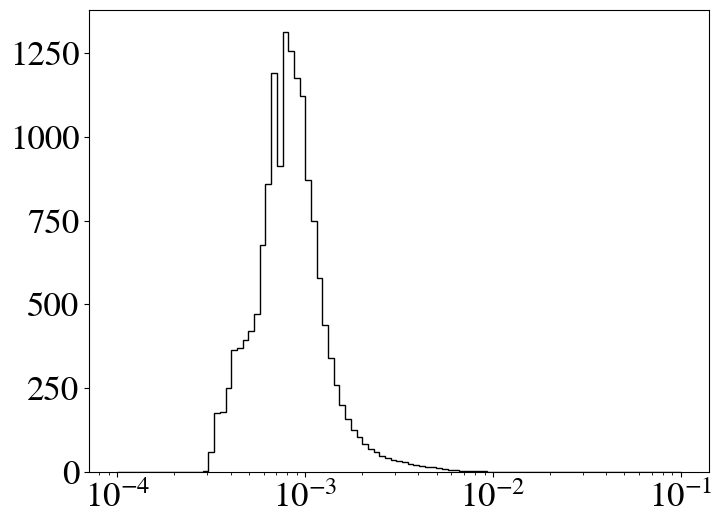

In [45]:
plt.hist(t_polar, 
         bins=np.logspace(-4, -1, 100),
         histtype='step', 
         color='black', 
         density=True,
         label='Polarization cut'
         )
plt.xscale('log')

print(f"Median Polarization cut: {np.median(t_polar)} s")
print(f"MAD Polarization cut: {np.median(np.abs(t_polar - np.median(t_polar)))} s")
print(f"Mean Polarization cut: {np.mean(t_polar)} s")
print(f"Std Polarization cut: {np.std(t_polar)} s")

Median PWF: 0.0007255077362060547 s
MAD PWF: 8.177757263183594e-05 s
Mean PWF: 0.0007507652226732092 s
Std PWF: 0.0005316720804442185 s


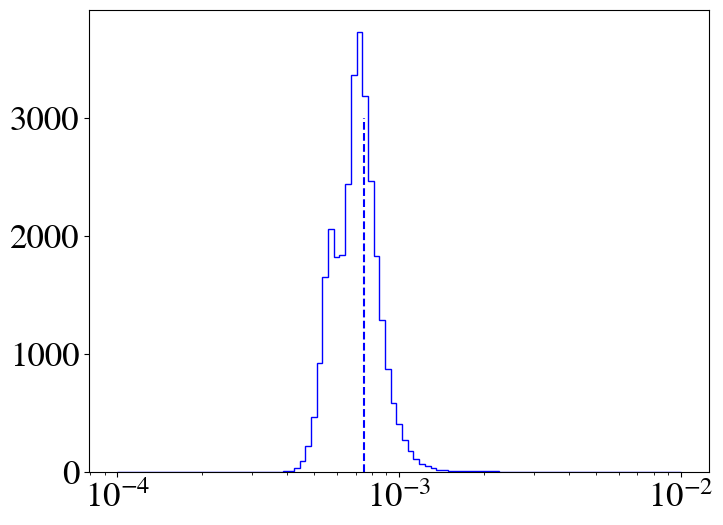

In [44]:
plt.hist(times_PWF, 
         bins=np.logspace(-4, -2, 100), 
         histtype='step', 
         color='blue', 
         label='PWF',
         density=True
         )
plt.xscale('log')
plt.plot(np.mean(times_PWF)*np.ones(2), 
         [0, 3000], 
         color='blue', 
         linestyle='--', 
         label='Mean PWF'
         )

print(f"Median PWF: {np.median(times_PWF)} s")
print(f"MAD PWF: {np.median(np.abs(times_PWF - np.median(times_PWF)))} s")
print(f"Mean PWF: {np.mean(times_PWF)} s")
print(f"Std PWF: {np.std(times_PWF)} s")

Median SWF: 0.9272603988647461 s
MAD SWF: 0.26227521896362305 s
Mean SWF: 1.2747220240311385 s
Std SWF: 1.021038871722626 s


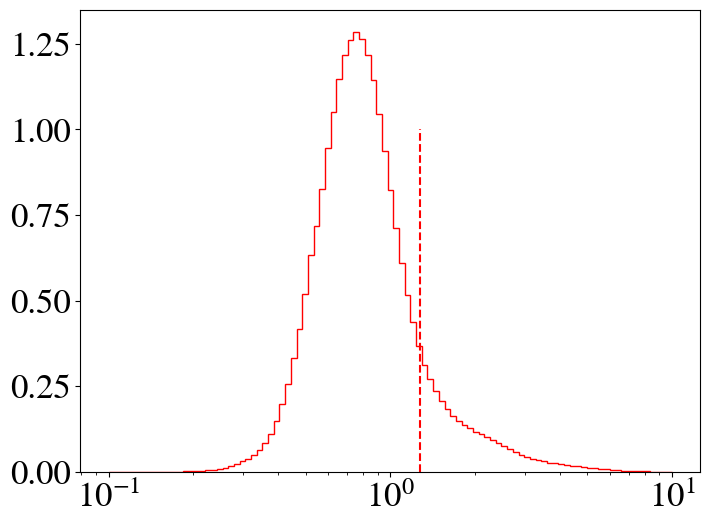

In [43]:
plt.hist(times_SWF, 
         bins=np.logspace(-1, 1, 100), 
         histtype='step', 
         color='red', 
         label='SWF',
         density=True
         )
plt.xscale('log')
plt.plot(np.mean(times_SWF)*np.ones(2), 
         [0, 1], 
         color='red', 
         linestyle='--', 
         label='Mean SWF'
         )

print(f"Median SWF: {np.median(times_SWF)} s")
print(f"MAD SWF: {np.median(np.abs(times_SWF - np.median(times_SWF)))} s")
print(f"Mean SWF: {np.mean(times_SWF)} s")
print(f"Std SWF: {np.std(times_SWF)} s")

Median ADF: 0.8089578151702881 s
MAD ADF: 0.7661139965057373 s
Mean ADF: 6.501039524893191 s
Std ADF: 13.386222513788475 s


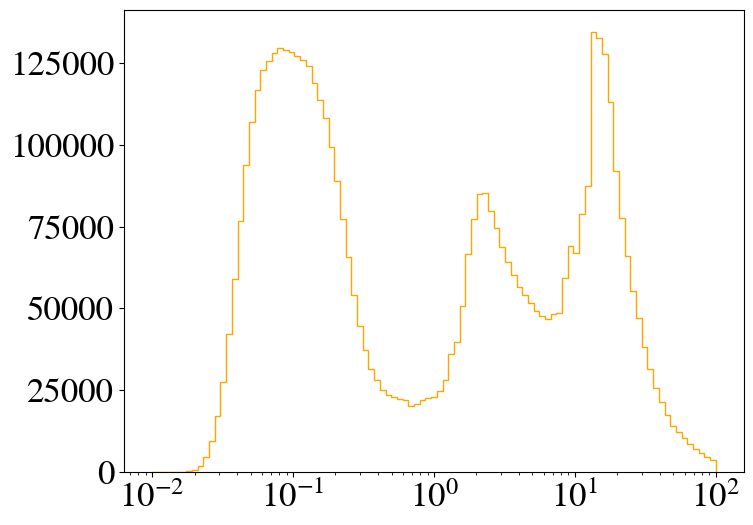

In [42]:
plt.hist(times_ADF, 
         bins=np.logspace(-2, 2, 100), 
         histtype='step', 
         color='orange', 
         label='ADF',
        #  density=True
         )
plt.xscale('log')
plt.plot(np.mean(times_ADF)*np.ones(2), 
         [0, 1], 
         color='orange', 
         linestyle='--', 
         label='Mean ADF'
         )
plt.plot(np.median(times_ADF)*np.ones(2), 
         [0, 1], 
         color='orange', 
         linestyle='--', 
         label='Median ADF'
         )



print(f"Median ADF: {np.median(times_ADF)} s")
print(f"MAD ADF: {np.median(np.abs(times_ADF - np.median(times_ADF)))} s")
print(f"Mean ADF: {np.mean(times_ADF)} s")
print(f"Std ADF: {np.std(times_ADF)} s")

Median Cluster: 4.317162281363892e-07 s
MAD Cluster: 3.9510108387014365e-08 s
Mean Cluster: 9.328935240362725e-07 s
Std Cluster: 1.4387698981288908e-06 s


/scratch/users/j/jlavoisier/ipykernel_434484/2239472461.py:3: RuntimeWarning: invalid value encountered in scalar divide
  t_cluster_per_event = np.array([np.float64(t_cluster_RUN[run])/len(parasite_time[run]) for run in t_cluster_RUN.keys()])


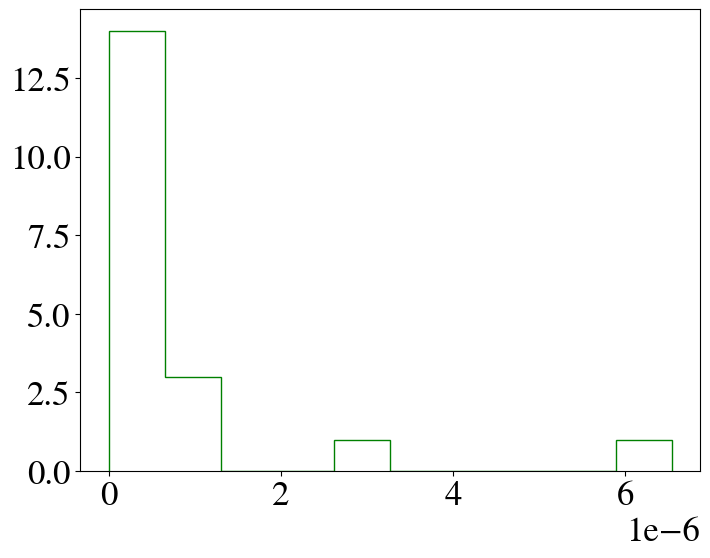

In [55]:
parasite_time = np.load(f"/sps/grand/jlavoisier/code/quantification/check_data/data/time_parasites.npy", allow_pickle=True).item()

t_cluster_per_event = np.array([np.float64(t_cluster_RUN[run])/len(parasite_time[run]) for run in t_cluster_RUN.keys()])

t_cluster_per_event = t_cluster_per_event[np.logical_not(np.isnan(t_cluster_per_event))]
# print(t_cluster_RUN)

plt.hist(t_cluster_per_event, 
        #  bins=np.logspace(-2, 1, 100), 
         histtype='step', 
         color='green', 
         label='Cluster',
        #  density=True
         )

print(f"Median Cluster: {np.median(t_cluster_per_event)} s")
print(f"MAD Cluster: {np.median(np.abs(t_cluster_per_event - np.median(t_cluster_per_event)))} s")
print(f"Mean Cluster: {np.mean(t_cluster_per_event)} s")
print(f"Std Cluster: {np.std(t_cluster_per_event)} s")